# Visualize Quantized Averaged Entropy

This Visualize notebook loads the cache produced by `Generate-quantized-averaged-entropy-data.ipynb` and reproduces the coarse-grained state-distribution entropy table at trajectory length $T=1000$ and the empirical state-distribution entropy figure as a function of trajectory length for the numerical input families presented in **Main Numerical Input Suite and Next-State Extrapolation**. Both results use 100 equal-width bins with shared edges and summarize the same 20 realizations by their mean and sample standard deviation.


Load plotting dependencies and cached entropy statistics.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import to_rgb

DATA_PATH = Path("quantized_averaged_entropy_100_bins.npz")
FIGURE_PATH = Path("state_distribution_entropy.pdf")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} was not found. Run Generate-quantized-averaged-entropy-data.ipynb first."
    )

# Load cached table and plotting data
with np.load(DATA_PATH, allow_pickle=False) as archive:
    saved = {name: archive[name] for name in archive.files}

schema_version = int(saved["schema_version"])
n_bins = int(saved["n_bins"])
n_replicates = int(saved["n_replicates"])
n_states = int(saved["n_states"])
data_names = saved["data_names"].astype(str)
display_names = saved["display_names"].astype(str)
context_lengths = saved["context_lengths"].astype(int)
table_entropy_mean = saved["table_entropy_mean"].astype(float)
table_entropy_std = saved["table_entropy_std"].astype(float)
figure_entropy_mean = saved["figure_entropy_mean"].astype(float)
figure_entropy_std = saved["figure_entropy_std"].astype(float)

print(f"Loaded {DATA_PATH}")
print(f"Inputs: {len(data_names)} | Replicates: {n_replicates} | Bins: {n_bins}")


Loaded quantized_averaged_entropy_100_bins.npz
Inputs: 10 | Replicates: 20 | Bins: 100


Display the 100-bin entropy summary used for the manuscript table.


In [2]:
# Format mean plus or minus sample standard deviation at T=1000
report_table = pd.DataFrame({
    "Input type": display_names,
    "Entropy (bits)": [
        f"{mean:.3f} ± {std:.3f}"
        for mean, std in zip(table_entropy_mean, table_entropy_std)
    ],
})

display(report_table)


,Input type,Entropy (bits)
0,Constant sampled,0.000 ± 0.000
1,Logistic r=3.2 (period 2),1.000 ± 0.000
2,Logistic r=3.5 (period 4),2.000 ± 0.000
3,Logistic r=3.55 (period 8),3.000 ± 0.000
4,Logistic r=3.566 (period 16),3.625 ± 0.000
5,Logistic r=3.5692 (period 32),4.039 ± 0.001
6,Logistic r=3.5698 (period 64),4.293 ± 0.002
7,Logistic r=3.9 (chaotic),6.222 ± 0.057
8,Logistic r=4.0 (chaotic),6.295 ± 0.053
9,Lorenz,6.360 ± 0.022


Define display settings, endpoint labels, and line styles shared by the entropy figure.


In [3]:
FIGSIZE = (6.4, 4.5)
INLINE_DPI = 150
FONT_SCALE = 1.15 * 1.10
AXIS_LABEL_SIZE = 10.8 * FONT_SCALE
TICK_LABEL_SIZE = 9.0 * FONT_SCALE
ENDPOINT_LABEL_SIZE = 8.0 * FONT_SCALE
BAND_ALPHA = 0.15
RIGHT_MARGIN = 140

STYLE_MAP = {
    "Constant sampled": dict(color="#D8D7E6", linestyle="-", linewidth=2.0),
    "Logistic r=3.2": dict(color="#C6D9F1", linestyle="-", linewidth=2.0),
    "Logistic r=3.5": dict(color="#A9C8EA", linestyle="-", linewidth=2.0),
    "Logistic r=3.55": dict(color="#83B2DC", linestyle="-", linewidth=2.0),
    "Logistic r=3.566": dict(color="#5F98CA", linestyle="-", linewidth=2.0),
    "Logistic r=3.5692": dict(color="#3E78B2", linestyle="-", linewidth=2.2),
    "Logistic r=3.5698": dict(color="#24518A", linestyle="-", linewidth=2.2),
    "Logistic r=3.9": dict(color="#E68169", linestyle="-.", linewidth=2.4),
    "Logistic r=4.0": dict(color="#C8525E", linestyle="-.", linewidth=2.4),
    "Lorenz": dict(color="#98334F", linestyle="-.", linewidth=2.8),
}

ENDPOINT_LABELS = {
    "Constant sampled": "Constant",
    "Logistic r=3.2": "Period 2",
    "Logistic r=3.5": "Period 4",
    "Logistic r=3.55": "Period 8",
    "Logistic r=3.566": "Period 16",
    "Logistic r=3.5692": "Period 32",
    "Logistic r=3.5698": "Period 64",
    "Logistic r=3.9": "r=3.9",
    "Logistic r=4.0": "r=4.0",
    "Lorenz": "Lorenz",
}

ENDPOINT_Y_OFFSETS = {
    "Logistic r=3.5692": -0.05,
    "Logistic r=3.5698": 0.05,
    "Logistic r=3.9": -0.22,
    "Logistic r=4.0": 0.00,
    "Lorenz": 0.20,
}


def line_style(data_name):
    style = STYLE_MAP[data_name].copy()
    style.update(marker="o", markersize=4.0)
    if data_name == "Lorenz":
        style["zorder"] = 5
    elif data_name in {"Logistic r=3.9", "Logistic r=4.0"}:
        style["zorder"] = 4
    else:
        style["zorder"] = 2
    return style


Plot state-distribution entropy as mean plus or minus one sample standard deviation across realizations.


Saved state_distribution_entropy.pdf


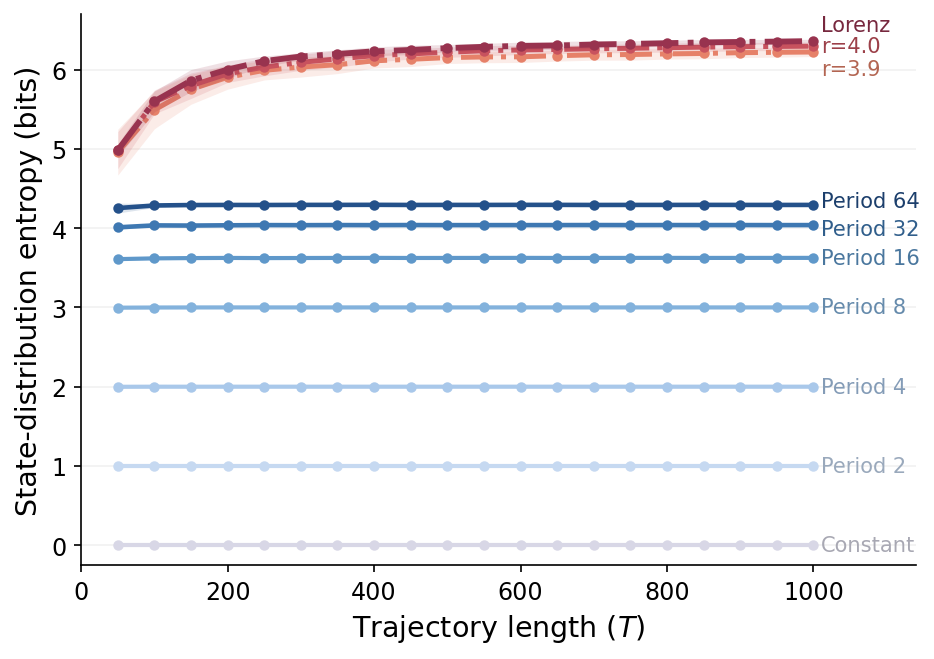

In [4]:
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=INLINE_DPI)
x = context_lengths.astype(float)

# Draw curves and sample-standard-deviation bands in the cached input order
for input_index, data_name in enumerate(data_names):
    mean = figure_entropy_mean[input_index]
    std = figure_entropy_std[input_index]
    style = line_style(data_name)

    ax.plot(x, mean, **style)
    ax.fill_between(
        x,
        np.maximum(mean - std, 0.0),
        mean + std,
        color=style["color"],
        alpha=BAND_ALPHA,
        linewidth=0,
        zorder=max(style["zorder"] - 0.5, 0),
    )

    label_color = tuple(0.78 * channel for channel in to_rgb(style["color"]))
    ax.text(
        x[-1] + 10.0,
        mean[-1] + ENDPOINT_Y_OFFSETS.get(data_name, 0.0),
        ENDPOINT_LABELS[data_name],
        color=label_color,
        fontsize=ENDPOINT_LABEL_SIZE,
        ha="left",
        va="center",
        clip_on=False,
    )

ax.set_xticks(np.arange(0, n_states + 1, 200))
ax.set_xlim(0, n_states + RIGHT_MARGIN)
ax.set_ylim(bottom=-0.25)
ax.set_xlabel("Trajectory length ($T$)", fontsize=AXIS_LABEL_SIZE)
ax.set_ylabel("State-distribution entropy (bits)", fontsize=AXIS_LABEL_SIZE)
ax.tick_params(axis="both", which="major", labelsize=TICK_LABEL_SIZE)
ax.set_axisbelow(True)
ax.grid(True, axis="y", alpha=0.18, linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURE_PATH, format="pdf", bbox_inches="tight", pad_inches=0.02)
print(f"Saved {FIGURE_PATH}")
plt.show()
